# Taller 04: Descubriendo Patrones Musicales con Spotify

## 1. Descripción del Caso
Imagina que trabajas como Data Scientist en una plataforma de streaming musical emergente. El equipo de producto quiere mejorar el sistema de recomendación, pero no tienen etiquetas claras para ciertos tipos de canciones.

Te entregan este conjunto de datos sobre 999 canciones y sus caracteristicas https://www.kaggle.com/datasets/glowstudygram/spotify-songs-and-artists-dataset

El objetivo de la actividad es usar algoritmos de agrupamiento (Clustering) para agrupar las canciones más populares del 2023 basándote únicamente en sus características de audio, ignorando el género o el artista. Luego, deberás interpretar qué representa cada grupo.

## 2. Objetivos de Aprendizaje
* Limpieza de datos.
* Estandarización de variables.
* Reducción de dimensionalidad (PCA).
* Clustering (K-Means o DBScan).
* Interpretación de resultados.

### Bloque 1: Configuración y Carga de Datos
Importa las librerías necesarias y carga el dataset.

In [4]:
# 1. Importación de Librerías
import pandas as pd
import seaborn as sns
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
data = pd.read_csv("spotifydataset.csv")
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         1000 non-null   int64  
 1   artist_name        1000 non-null   str    
 2   genres             837 non-null    str    
 3   followers          1000 non-null   int64  
 4   artist_popularity  1000 non-null   int64  
 5   artist_url         1000 non-null   str    
 6   track_name         1000 non-null   str    
 7   album_name         1000 non-null   str    
 8   release_date       1000 non-null   str    
 9   duration_ms        1000 non-null   int64  
 10  explicit           1000 non-null   bool   
 11  track_popularity   1000 non-null   int64  
 12  danceability       1000 non-null   float64
 13  energy             1000 non-null   float64
 14  key                1000 non-null   int64  
 15  loudness           1000 non-null   float64
 16  mode               1000 non-null   i

### Bloque 2: Limpieza y Preparación
Se debe trabajar solamente con las columnas que describen como es la canción en terminos auditivos:

- track_popularity
- danceability
- energy
- key
- loudness
- mode
- speechiness
- acousticness
- instrumentalness
- liveness
- valence
- tempo

No se deben usar columnas como el artista o genero para evitar sesgos en la agrupación

In [5]:
col_spotify = [
    "track_popularity",
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

data_audio = data[col_spotify].copy()

print(data_audio.head())

   track_popularity  danceability  energy  key  loudness  mode  speechiness  \
0                89         0.645   0.646    5    -8.334     1       0.0427   
1                85         0.795   0.630    7    -5.854     0       0.0434   
2                83         0.506   0.362   10    -9.480     1       0.0416   
3                80         0.650   0.825    0    -4.645     1       0.0325   
4                79         0.787   0.775    1    -6.614     1       0.0548   

   acousticness  instrumentalness  liveness  valence    tempo  
0        0.0615          0.000030    0.0740    0.295  115.842  
1        0.1570          0.000000    0.0732    0.447   97.998  
2        0.6700          0.000000    0.1760    0.385   84.726  
3        0.0215          0.000024    0.0936    0.593  118.091  
4        0.1900          0.000065    0.1130    0.787  118.998  


### Bloque 3: Reducción de Dimensionalidad (PCA)
Reduce los datos a 2 componentes principales para poder visualizarlos en un gráfico 2D.

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_audio)

display(data_scaled)

pd.DataFrame(data_scaled,columns=data_audio.columns)

pca = PCA(n_components=2)
data_pca = pca.fit_transform(data_scaled)
data_pca


array([[ 1.23867878,  0.20082268, -0.07019166, ..., -0.78971516,
        -0.95214957, -0.22473366],
       [ 1.0711256 ,  1.09815371, -0.14731349, ..., -0.79521791,
        -0.29917199, -0.86111871],
       [ 0.98734901, -0.63070407, -1.43910416, ..., -0.08811359,
        -0.56551811, -1.33444882],
       ...,
       [ 0.02391822,  0.80502557,  1.53008632, ..., -1.1198806 ,
         0.58578447,  1.12931429],
       [-0.01797008,  0.82297219,  0.94203236, ...,  3.8257226 ,
        -0.49248772, -0.6551602 ],
       [-0.05985837,  1.46905053,  0.49858184, ...,  1.62461965,
         0.26359158, -1.03683431]], shape=(1000, 12))

array([[ 0.06318536,  0.12911142],
       [ 0.60988526,  1.54281623],
       [-1.72577279,  1.12004716],
       ...,
       [ 1.66460061, -0.04923638],
       [ 1.58614799, -1.21383465],
       [ 1.44047979,  0.29105343]], shape=(1000, 2))

Text(0, 0.5, 'Componente principal 2')

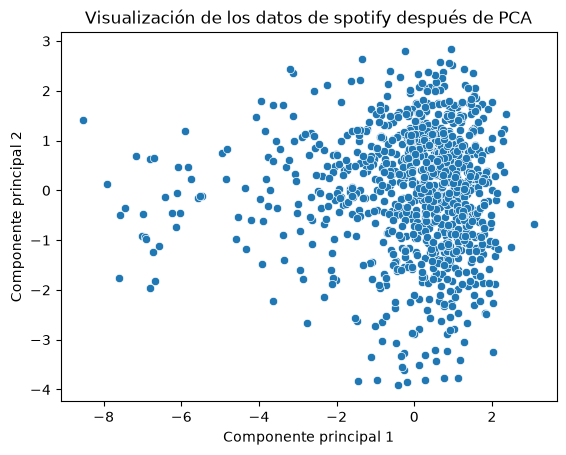

In [7]:
import seaborn as sns

sns.scatterplot(x=data_pca[:, 0], y=data_pca[:, 1])
plt.title("Visualización de los datos de spotify después de PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

### Bloque 4: Modelado (Usa K-Means o DB Scan para generar los clusters)

Text(0, 0.5, 'Componente principal 2')

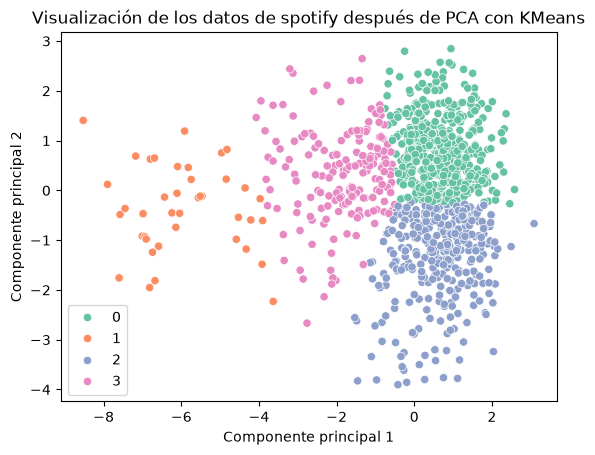

In [8]:
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(data_pca)

sns.scatterplot(x=data_pca[:, 0], y=data_pca[:, 1], hue=kmeans.labels_, palette='Set2')
plt.title("Visualización de los datos de spotify después de PCA con KMeans")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

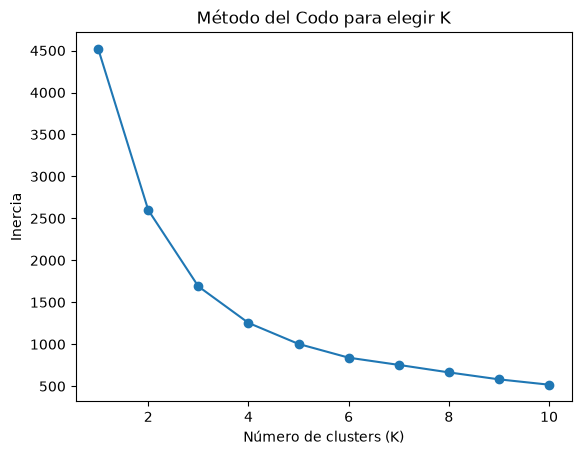

In [9]:
inertias = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(data_pca)
    inertias.append(km.inertia_)

plt.plot(k_range, inertias, marker='o')
plt.title('Método del Codo para elegir K')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inercia')
plt.show()

Text(0, 0.5, 'Componente principal 2')

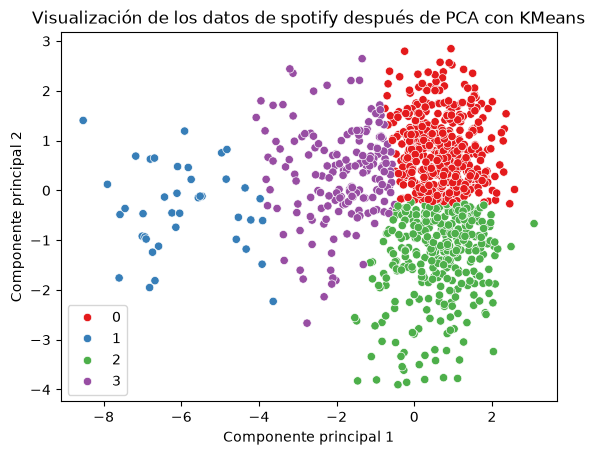

In [10]:
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(data_pca)

sns.scatterplot(x=data_pca[:, 0], y=data_pca[:, 1], hue=kmeans.labels_, palette='Set1')
plt.title("Visualización de los datos de spotify después de PCA con KMeans")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

### Bloque 5: Visualización y Análisis
Genera visualizaciones que permitan interpretar qué significa cada grupo.

In [11]:
kmeans.labels_

array([0, 0, 3, 0, 0, 2, 0, 3, 2, 0, 3, 0, 3, 0, 3, 3, 2, 3, 0, 3, 0, 2,
       0, 2, 0, 0, 0, 0, 3, 0, 2, 3, 2, 3, 3, 3, 0, 3, 0, 0, 3, 2, 0, 0,
       2, 0, 0, 2, 0, 0, 0, 2, 3, 2, 2, 2, 2, 2, 2, 2, 0, 2, 0, 0, 0, 2,
       2, 0, 0, 0, 2, 0, 0, 0, 0, 2, 0, 0, 0, 3, 2, 0, 2, 0, 0, 0, 0, 0,
       2, 0, 2, 2, 2, 0, 0, 2, 0, 2, 2, 2, 3, 3, 0, 3, 3, 2, 2, 3, 3, 3,
       0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 2, 0, 0, 2, 0, 0, 0, 0, 0, 2, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 2, 2, 2, 0, 2, 2, 2, 2,
       2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3,
       3, 0, 0, 3, 0, 0, 3, 2, 3, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 3, 3, 0,
       3, 0, 3, 3, 0, 0, 0, 0, 2, 0, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 0, 2, 0, 0, 2, 0, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       0, 2, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 3, 0, 0, 0, 2, 3, 3, 2, 3, 3, 0, 0, 2, 2,

In [12]:
data_clusters = pd.concat([pd.DataFrame(data_audio),pd.DataFrame(kmeans.labels_,columns=[("Cluster")])],axis=1)

In [13]:
data_clusters.groupby('Cluster').mean()

display(data_clusters)

,track_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,Cluster
0,89,0.645,0.646,5,-8.334,1,0.0427,0.0615,0.000030,0.0740,0.295,115.842,0
1,85,0.795,0.630,7,-5.854,0,0.0434,0.1570,0.000000,0.0732,0.447,97.998,0
2,83,0.506,0.362,10,-9.480,1,0.0416,0.6700,0.000000,0.1760,0.385,84.726,3
3,80,0.650,0.825,0,-4.645,1,0.0325,0.0215,0.000024,0.0936,0.593,118.091,0
4,79,0.787,0.775,1,-6.614,1,0.0548,0.1900,0.000065,0.1130,0.787,118.998,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,69,0.751,0.708,0,-5.653,1,0.0545,0.0482,0.000018,0.1070,0.509,108.970,0
996,64,0.792,0.701,6,-7.198,0,0.2830,0.1050,0.000000,0.7610,0.251,103.890,2
997,60,0.746,0.978,9,-5.324,1,0.0978,0.0555,0.000041,0.0260,0.653,153.809,0
998,59,0.749,0.856,2,-5.833,1,0.2350,0.1070,0.000000,0.7450,0.402,103.773,2


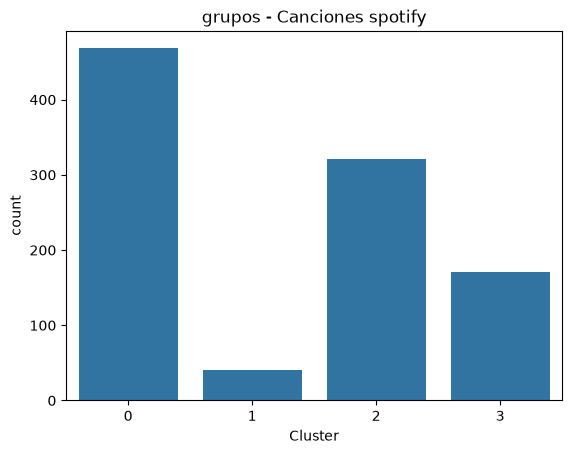

In [14]:
sns.countplot(data=data_clusters, x="Cluster")
plt.title('grupos - Canciones spotify')
plt.show()

<Axes: ylabel='Count'>

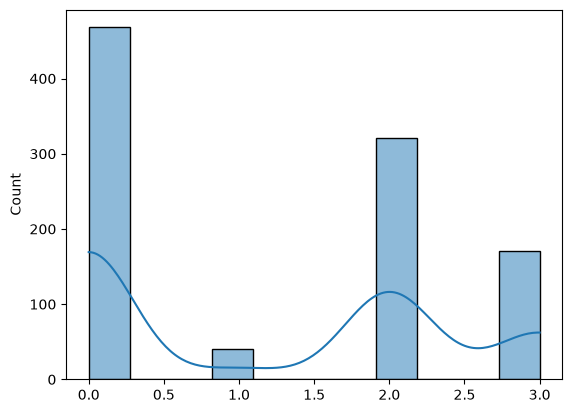

In [15]:
sns.histplot(data=kmeans.labels_,kde=True)

<Axes: xlabel='track_popularity', ylabel='danceability'>

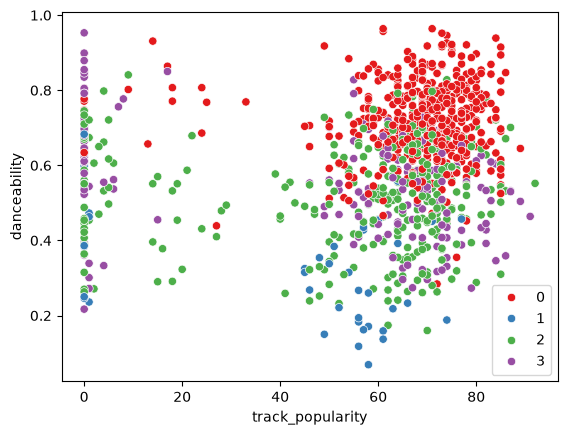

In [16]:
sns.scatterplot(data=data_clusters, x="track_popularity", y="danceability",hue=kmeans.labels_, palette='Set1')

<Axes: xlabel='tempo', ylabel='energy'>

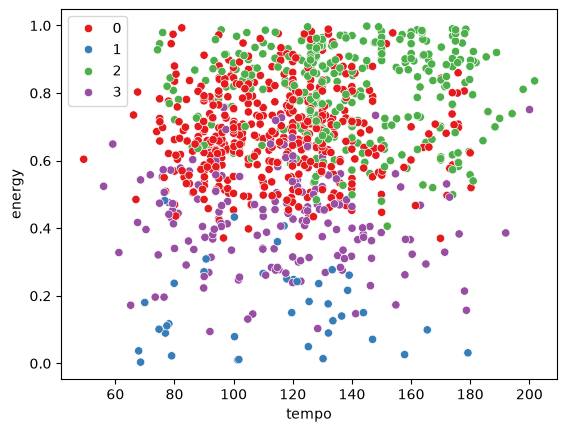

In [17]:
sns.scatterplot(data=data_clusters, x="tempo", y="energy",hue=kmeans.labels_, palette='Set1')

<Axes: xlabel='Cluster', ylabel='tempo'>

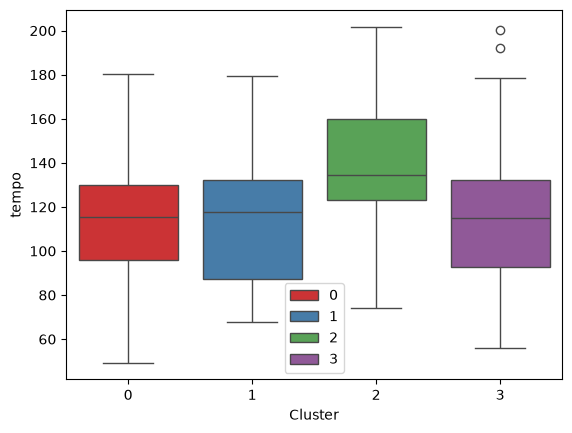

In [18]:
sns.boxplot(data=data_clusters, x="Cluster",y="tempo",hue=kmeans.labels_, palette='Set1')

<Axes: xlabel='acousticness', ylabel='energy'>

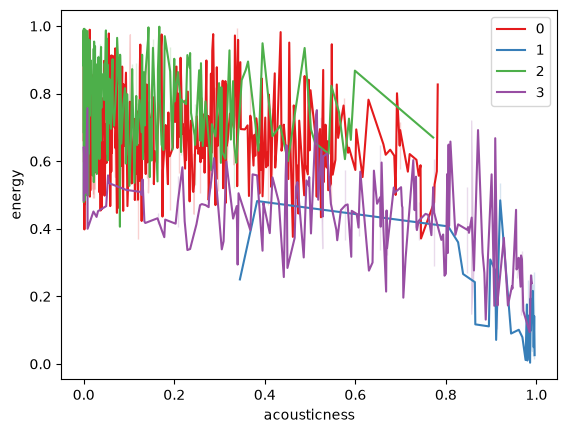

In [19]:
sns.lineplot(data=data_clusters, x="acousticness",y="energy",hue=kmeans.labels_, palette='Set1')

<Axes: xlabel='danceability', ylabel='instrumentalness'>

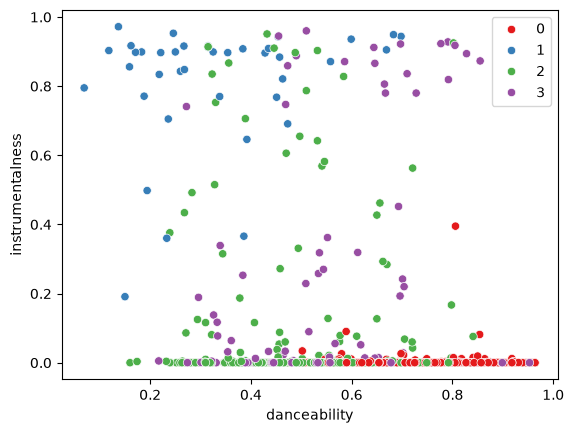

In [20]:
sns.scatterplot(data=data_clusters,x="danceability",y="instrumentalness",hue=kmeans.labels_, palette='Set1')

### Conclusiones

Plantear 3 conclusiones propias basadas en los resultados obtenidos

# CONCLUSION 1 
### Se puede concluir quue las canciones con un indice mas alto en instrumentalidad son las menos prefereidas, por ende en en la lista que maneja spotify son las menos populares. 

# CONCLUSION 2 
### Tambien se puede notar que las canciones mas populares poseen un indice de energia mas alto, lo que genera que muchos grupos de personas eligan escuchar de manera diaria ademas un factor importante es la danceabilidad de la cancion, en este caso, entre mas danceable es, mas energia posee y por ende mas popular es 

# CONCLUSION 3 
### Se puede notar de manera clara que las canciones mas rapidas, es decir con un tempo mas alto, son mas energeticas pero no solo por eso las hacen mas populares, por eso su indice no es tan alto comparado con la conclusion anterior. Se puede notar de manera detallada que el factor popularidad si influye de manera determinada. Queda claro que las canciones mas instrumentales son las menos populares y las menos opcionales que salgan de manera repetitiva en las playlist